# Group 3 Class Project
## CSE 40467
## Part 1



In [ ]:
import pandas as pd
import csv
import numpy as np
import seaborn as sns
import string
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.feature_extraction import text
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

## **Our Dataset**
 We will be working with the [IMDB Movie Dataset](https://www.kaggle.com/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows). This dataset contains the top 1000 movies and tv shows. It has attributes for series_title, release_year, runtime, genre, IMDB_rating, gross, and director.

In [ ]:
imdb = pd.read_csv("imdb_top_1000.csv")

In [ ]:
imdb

,Series_Title,Released_Year,Genre,IMDB_Rating,Director,Star1,Star2,Star3,Star4,Gross,...,Animation,Family,War,Mystery,Music,Horror,Musical,Film-Noir,Sport,Runtime in Minutes
0,The Shawshank Redemption,1994,Drama,1.000000,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,"28,341,469",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.351449
1,The Godfather,1972,"Crime, Drama",0.941176,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,"134,966,411",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.471014
2,The Dark Knight,2008,"Action, Crime, Drama",0.823529,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,"534,858,444",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.387681
3,The Godfather: Part II,1974,"Crime, Drama",0.823529,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,"57,300,000",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.568841
4,12 Angry Men,1957,"Crime, Drama",0.823529,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,"4,360,000",...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.184783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Breakfast at Tiffany's,1961,"Comedy, Drama, Romance",0.000000,Blake Edwards,Audrey Hepburn,George Peppard,Patricia Neal,Buddy Ebsen,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.253623
996,Giant,1956,"Drama, Western",0.000000,George Stevens,Elizabeth Taylor,Rock Hudson,James Dean,Carroll Baker,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.565217
997,From Here to Eternity,1953,"Drama, Romance, War",0.000000,Fred Zinnemann,Burt Lancaster,Montgomery Clift,Deborah Kerr,Donna Reed,"30,500,000",...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.264493
998,Lifeboat,1944,"Drama, War",0.000000,Alfred Hitchcock,Tallulah Bankhead,John Hodiak,Walter Slezak,William Bendix,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.188406


## **Our Data Pre-Processing**


Balancing our Genre Column

In [ ]:
genres_with_one_movie = len(imdb['Genre'].value_counts()[imdb['Genre'].value_counts() == 1])
print('The amount of genres that have only one movie in the database:', genres_with_one_movie, '\n')
imdb['Genre'].value_counts()[imdb['Genre'].value_counts() == 1]

The amount of genres that have only one movie in the database: 72 



Genre
Animation, Biography, Crime    1
Crime, Drama, History          1
Adventure, Biography, Crime    1
Fantasy, Horror                1
Adventure, Horror, Sci-Fi      1
                              ..
Adventure, Thriller            1
Animation, Action, Sci-Fi      1
Action, Crime, Comedy          1
Animation, Crime, Mystery      1
Adventure, Comedy, War         1
Name: count, Length: 72, dtype: int64

In [ ]:
def update_genre_columns(row):
    genres = row['Genre'].split(', ')
    for genre in genres:
        if genre not in imdb.columns:
            imdb[genre] = 0  # Create a new column for the genre if it doesn't exist
        imdb.at[row.name, genre] = 1  # Set the value to 1 in the corresponding genre column
    return row

# Apply the function to each row
imdb.apply(update_genre_columns, axis=1)

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,https://m.media-amazon.com/images/M/MV5BNGEwMT...,Breakfast at Tiffany's,1961,A,115 min,"Comedy, Drama, Romance",7.6,A young New York socialite becomes interested ...,76.0,Blake Edwards,Audrey Hepburn,George Peppard,Patricia Neal,Buddy Ebsen,166544,NaN
996,https://m.media-amazon.com/images/M/MV5BODk3Yj...,Giant,1956,G,201 min,"Drama, Western",7.6,Sprawling epic covering the life of a Texas ca...,84.0,George Stevens,Elizabeth Taylor,Rock Hudson,James Dean,Carroll Baker,34075,NaN
997,https://m.media-amazon.com/images/M/MV5BM2U3Yz...,From Here to Eternity,1953,Passed,118 min,"Drama, Romance, War",7.6,"In Hawaii in 1941, a private is cruelly punish...",85.0,Fred Zinnemann,Burt Lancaster,Montgomery Clift,Deborah Kerr,Donna Reed,43374,"30,500,000"
998,https://m.media-amazon.com/images/M/MV5BZTBmMj...,Lifeboat,1944,NaN,97 min,"Drama, War",7.6,Several survivors of a torpedoed merchant ship...,78.0,Alfred Hitchcock,Tallulah Bankhead,John Hodiak,Walter Slezak,William Bendix,26471,NaN


In [ ]:
#we see that our new columns have been added to our dataframe
print(imdb.columns.tolist())

#then we see that these new columns have only two unique value (that is 0 if that columns' genre is not in the movie, and 1 if it is)
imdb.nunique()


['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate', 'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director', 'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross', 'Drama', 'Crime', 'Action', 'Adventure', 'Biography', 'History', 'Sci-Fi', 'Romance', 'Western', 'Fantasy', 'Comedy', 'Thriller', 'Animation', 'Family', 'War', 'Mystery', 'Music', 'Horror', 'Musical', 'Film-Noir', 'Sport']


Poster_Link      1000
Series_Title      999
Released_Year     100
Certificate        16
Runtime           140
Genre             202
IMDB_Rating        17
Overview         1000
Meta_score         63
Director          548
Star1             660
Star2             841
Star3             891
Star4             939
No_of_Votes       999
Gross             823
Drama               2
Crime               2
Action              2
Adventure           2
Biography           2
History             2
Sci-Fi              2
Romance             2
Western             2
Fantasy             2
Comedy              2
Thriller            2
Animation           2
Family              2
War                 2
Mystery             2
Music               2
Horror              2
Musical             2
Film-Noir           2
Sport               2
dtype: int64

In [ ]:
#want a list of all the individual genres that are our new columns
each_genre = []
for index, row in imdb.iterrows():
    each_genre.append(row['Genre'])


# Empty list to store individual genres
individual_genres = []

# Iterate through each item in the list
for item in each_genre:
    # Split the item by comma and strip any leading or trailing whitespaces
    genres = [genre.strip() for genre in item.split(',')]
    # Add each genre to the list of individual genres
    if item not in individual_genres:
        individual_genres.extend(genres)

new_columns = []
#need to delete duplicates
for item in individual_genres:
    if item not in new_columns:
        new_columns.append(item)


print('the amount of genres we have:', len(new_columns))
print('They are: ', new_columns)

the amount of genres we have: 21
They are:  ['Drama', 'Crime', 'Action', 'Adventure', 'Biography', 'History', 'Sci-Fi', 'Romance', 'Western', 'Fantasy', 'Comedy', 'Thriller', 'Animation', 'Family', 'War', 'Mystery', 'Music', 'Horror', 'Musical', 'Film-Noir', 'Sport']


In [ ]:
#as we can see here in the head, the work we did is reflective through the new columns in comparison with the 'Genre' columns
columns_want = []
columns_want.append('Genre')
for i in new_columns:
    columns_want.append(i)
imdb[columns_want].head(10)

,Genre,Drama,Crime,Action,Adventure,Biography,History,Sci-Fi,Romance,Western,...,Thriller,Animation,Family,War,Mystery,Music,Horror,Musical,Film-Noir,Sport
0,Drama,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,"Crime, Drama",1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,"Action, Crime, Drama",1,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,"Crime, Drama",1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,"Crime, Drama",1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,"Action, Adventure, Drama",1,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,"Crime, Drama",1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,"Biography, Drama, History",1,0,0,0,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,"Action, Adventure, Sci-Fi",0,0,1,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
9,Drama,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
for i in new_columns:
    print(i, ": ", imdb[i].sum()/len(imdb))
# we see that the top five genres are:
##drama with 72.4%
##comedy with 23.3%
##crime with 20.9%
##adventure with 19.6%
##action with 18.9%

Drama :  0.724
Crime :  0.209
Action :  0.189
Adventure :  0.196
Biography :  0.109
History :  0.056
Sci-Fi :  0.067
Romance :  0.125
Western :  0.02
Fantasy :  0.066
Comedy :  0.233
Thriller :  0.137
Animation :  0.082
Family :  0.056
War :  0.051
Mystery :  0.099
Music :  0.035
Horror :  0.032
Musical :  0.017
Film-Noir :  0.019
Sport :  0.019


In [ ]:
#Diego suggestion
#You could check how many movies are only `drama.`
#If you have many `drama` movies with other categories, you may use the other categories and remove the column `drama`.
drama_count = imdb['Genre'].value_counts()['Drama']
print('Only dramas : ', drama_count)
print('Only dramas %: ', drama_count/len(imdb))

#I think we shouldn't do this suggestion and just leave it with what we have above with the new columns created for each category

Only dramas :  85
Only dramas %:  0.085


Balancing IMDB Ratings

In [ ]:
#list of columns
columns = imdb.columns.tolist()

In [ ]:
for i in columns:
    print(i, ': ', imdb[i].dtype)

Poster_Link :  object
Series_Title :  object
Released_Year :  object
Certificate :  object
Runtime :  object
Genre :  object
IMDB_Rating :  float64
Overview :  object
Meta_score :  float64
Director :  object
Star1 :  object
Star2 :  object
Star3 :  object
Star4 :  object
No_of_Votes :  int64
Gross :  object
Drama :  int64
Crime :  int64
Action :  int64
Adventure :  int64
Biography :  int64
History :  int64
Sci-Fi :  int64
Romance :  int64
Western :  int64
Fantasy :  int64
Comedy :  int64
Thriller :  int64
Animation :  int64
Family :  int64
War :  int64
Mystery :  int64
Music :  int64
Horror :  int64
Musical :  int64
Film-Noir :  int64
Sport :  int64


In [ ]:
#looking at float64 columns
print('Length of unique values in the column IMDB_Rating: ', imdb['IMDB_Rating'].nunique())
print(imdb['IMDB_Rating'].value_counts())
print('Are there any null values in IMDB_Rating? ', imdb['IMDB_Rating'].isnull().any())

Length of unique values in the column IMDB_Rating:  17
IMDB_Rating
7.7    157
7.8    151
8.0    141
8.1    127
7.6    123
7.9    106
8.2     67
8.3     44
8.4     31
8.5     20
8.6     15
8.7      5
8.8      5
8.9      3
9.0      3
9.2      1
9.3      1
Name: count, dtype: int64
Are there any null values in IMDB_Rating?  False


In [ ]:
# Standardization on IMDB Rating

## I think these do the same thing and we only need one or the other
#scaler = StandardScaler()
#imdb["IMDB_Rating"] = scaler.fit_transform(imdb[["IMDB_Rating"]])

imdb["IMDB_Rating"] = (imdb["IMDB_Rating"] - imdb["IMDB_Rating"].min())/(imdb["IMDB_Rating"].max() - imdb["IMDB_Rating"].min())

In [ ]:
print(imdb["IMDB_Rating"].value_counts())

IMDB_Rating
0.058824    157
0.117647    151
0.235294    141
0.294118    127
0.000000    123
0.176471    106
0.352941     67
0.411765     44
0.470588     31
0.529412     20
0.588235     15
0.647059      5
0.705882      5
0.764706      3
0.823529      3
0.941176      1
1.000000      1
Name: count, dtype: int64


In [ ]:
print('Length of unique values in the column Meta_score: ', imdb['Meta_score'].nunique())
imdb['Meta_score'].value_counts()
#Meta_score - Score earned by the movie

Length of unique values in the column Meta_score:  63


Meta_score
76.0    32
84.0    29
90.0    29
80.0    27
73.0    27
        ..
28.0     1
36.0     1
46.0     1
30.0     1
41.0     1
Name: count, Length: 63, dtype: int64

In [ ]:
# We will end up removing the meta_score so it does not need to be standardized

#scaler = StandardScaler()
#imdb["Meta_score"] = scaler.fit_transform(imdb[["Meta_score"]])
#imdb["Meta_score"] = (imdb["Meta_score"] - imdb["Meta_score"].min())/(imdb["Meta_score"].max() - imdb["Meta_score"].min())

In [ ]:
imdb['Meta_score'].value_counts()

Meta_score
76.0    32
84.0    29
90.0    29
80.0    27
73.0    27
        ..
28.0     1
36.0     1
46.0     1
30.0     1
41.0     1
Name: count, Length: 63, dtype: int64

In [ ]:
imdb.isna().sum()
#Certificate - Certificate earned by that movie
#Gross - Money earned by that movie
#Meta Score
##missing significant amount of data

Poster_Link        0
Series_Title       0
Released_Year      0
Certificate      101
Runtime            0
Genre              0
IMDB_Rating        0
Overview           0
Meta_score       157
Director           0
Star1              0
Star2              0
Star3              0
Star4              0
No_of_Votes        0
Gross            169
Drama              0
Crime              0
Action             0
Adventure          0
Biography          0
History            0
Sci-Fi             0
Romance            0
Western            0
Fantasy            0
Comedy             0
Thriller           0
Animation          0
Family             0
War                0
Mystery            0
Music              0
Horror             0
Musical            0
Film-Noir          0
Sport              0
dtype: int64

Create New Column for Integer Based Runtime Column

In [ ]:
#runtime into an integer based column
list_of_min = []
for runtime_str in imdb['Runtime']:
    min_str = runtime_str.split(' ')
    min_int = int(min_str[0])
    list_of_min.append(min_int)

imdb['Runtime in Minutes'] = list_of_min

imdb[['Runtime', 'Runtime in Minutes']].head(5)

,Runtime,Runtime in Minutes
0,142 min,142
1,175 min,175
2,152 min,152
3,202 min,202
4,96 min,96


Title Series Repeated

In [ ]:
imdb['Series_Title'].value_counts()[imdb['Series_Title'].value_counts() != 1]

Series_Title
Drishyam    2
Name: count, dtype: int64

In [ ]:
# The movie title is repeated because the movie was remade in a different year with a different director and cast
imdb[imdb['Series_Title'] == 'Drishyam']

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,...,Animation,Family,War,Mystery,Music,Horror,Musical,Film-Noir,Sport,Runtime in Minutes
87,https://m.media-amazon.com/images/M/MV5BYmY3Mz...,Drishyam,2013,U,160 min,"Crime, Drama, Thriller",0.411765,A man goes to extreme lengths to save his fami...,NaN,Jeethu Joseph,...,0,0,0,0,0,0,0,0,0,160
136,https://m.media-amazon.com/images/M/MV5BYmJhZm...,Drishyam,2015,UA,163 min,"Crime, Drama, Mystery",0.352941,Desperate measures are taken by a man who trie...,NaN,Nishikant Kamat,...,0,0,0,1,0,0,0,0,0,163


Deleting Columns

In [ ]:
# Remove columns we won't be using
imdb = imdb.drop(columns=['Poster_Link', 'Certificate', 'Meta_score', 'Overview', 'No_of_Votes', 'Runtime'], axis=1)
imdb

,Series_Title,Released_Year,Genre,IMDB_Rating,Director,Star1,Star2,Star3,Star4,Gross,...,Animation,Family,War,Mystery,Music,Horror,Musical,Film-Noir,Sport,Runtime in Minutes
0,The Shawshank Redemption,1994,Drama,1.000000,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,"28,341,469",...,0,0,0,0,0,0,0,0,0,142
1,The Godfather,1972,"Crime, Drama",0.941176,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,"134,966,411",...,0,0,0,0,0,0,0,0,0,175
2,The Dark Knight,2008,"Action, Crime, Drama",0.823529,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,"534,858,444",...,0,0,0,0,0,0,0,0,0,152
3,The Godfather: Part II,1974,"Crime, Drama",0.823529,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,"57,300,000",...,0,0,0,0,0,0,0,0,0,202
4,12 Angry Men,1957,"Crime, Drama",0.823529,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,"4,360,000",...,0,0,0,0,0,0,0,0,0,96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Breakfast at Tiffany's,1961,"Comedy, Drama, Romance",0.000000,Blake Edwards,Audrey Hepburn,George Peppard,Patricia Neal,Buddy Ebsen,NaN,...,0,0,0,0,0,0,0,0,0,115
996,Giant,1956,"Drama, Western",0.000000,George Stevens,Elizabeth Taylor,Rock Hudson,James Dean,Carroll Baker,NaN,...,0,0,0,0,0,0,0,0,0,201
997,From Here to Eternity,1953,"Drama, Romance, War",0.000000,Fred Zinnemann,Burt Lancaster,Montgomery Clift,Deborah Kerr,Donna Reed,"30,500,000",...,0,0,1,0,0,0,0,0,0,118
998,Lifeboat,1944,"Drama, War",0.000000,Alfred Hitchcock,Tallulah Bankhead,John Hodiak,Walter Slezak,William Bendix,NaN,...,0,0,1,0,0,0,0,0,0,97


In [ ]:
imdb.columns

Index(['Series_Title', 'Released_Year', 'Genre', 'IMDB_Rating', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'Gross', 'Drama', 'Crime', 'Action',
       'Adventure', 'Biography', 'History', 'Sci-Fi', 'Romance', 'Western',
       'Fantasy', 'Comedy', 'Thriller', 'Animation', 'Family', 'War',
       'Mystery', 'Music', 'Horror', 'Musical', 'Film-Noir', 'Sport',
       'Runtime in Minutes'],
      dtype='object')

In [ ]:
imdb.dtypes

Series_Title           object
Released_Year          object
Genre                  object
IMDB_Rating           float64
Director               object
Star1                  object
Star2                  object
Star3                  object
Star4                  object
Gross                  object
Drama                   int64
Crime                   int64
Action                  int64
Adventure               int64
Biography               int64
History                 int64
Sci-Fi                  int64
Romance                 int64
Western                 int64
Fantasy                 int64
Comedy                  int64
Thriller                int64
Animation               int64
Family                  int64
War                     int64
Mystery                 int64
Music                   int64
Horror                  int64
Musical                 int64
Film-Noir               int64
Sport                   int64
Runtime in Minutes      int64
dtype: object

Clustering Models

In [ ]:
numeric_columns = imdb.select_dtypes(include=['number']).columns.tolist()
numeric_columns

['IMDB_Rating',
 'Drama',
 'Crime',
 'Action',
 'Adventure',
 'Biography',
 'History',
 'Sci-Fi',
 'Romance',
 'Western',
 'Fantasy',
 'Comedy',
 'Thriller',
 'Animation',
 'Family',
 'War',
 'Mystery',
 'Music',
 'Horror',
 'Musical',
 'Film-Noir',
 'Sport',
 'Runtime in Minutes']

In [ ]:
# Normalize all numeric columns on a min-max scale
scaler = MinMaxScaler()
imdb[numeric_columns] = scaler.fit_transform(imdb[numeric_columns])

In [ ]:
imdb[numeric_columns].corr()

,IMDB_Rating,Drama,Crime,Action,Adventure,Biography,History,Sci-Fi,Romance,Western,...,Animation,Family,War,Mystery,Music,Horror,Musical,Film-Noir,Sport,Runtime in Minutes
IMDB_Rating,1.000000,0.059363,0.009792,-0.001092,0.004915,-0.017174,0.003778,0.027553,-0.032532,0.026304,...,-0.020419,-0.032551,0.054240,0.022122,-0.024217,-0.040807,-0.001070,0.020305,-0.011617,0.243096
Drama,0.059363,1.000000,0.047779,-0.341899,-0.433380,0.172883,0.130922,-0.192441,0.104845,-0.023649,...,-0.304683,-0.151237,0.071952,-0.050005,0.068896,-0.103820,-0.005330,-0.012388,0.069541,0.219798
Crime,0.009792,0.047779,1.000000,0.097365,-0.229014,-0.014056,-0.114500,-0.127910,-0.149663,-0.073432,...,-0.099843,-0.125197,-0.119162,0.109598,-0.084511,-0.079485,-0.048572,0.054567,-0.053522,0.010054
Action,-0.001092,-0.341899,0.097365,1.000000,0.295696,-0.078691,-0.073142,0.166899,-0.159292,0.004014,...,0.013983,-0.106470,-0.053860,-0.065946,-0.091937,-0.073260,-0.063485,-0.067184,-0.048475,0.065912
Adventure,0.004915,-0.433380,-0.229014,0.295696,1.000000,-0.108026,-0.054519,0.169953,-0.163766,0.037427,...,0.329874,0.098870,-0.045756,-0.146796,-0.094031,-0.061145,-0.045443,-0.050262,-0.068714,0.045876
Biography,-0.017174,0.172883,-0.014056,-0.078691,-0.108026,1.000000,0.305585,-0.093728,-0.122496,-0.049966,...,-0.069448,-0.029364,-0.066497,-0.115939,0.055611,-0.063593,-0.045996,-0.048676,0.162857,0.159173
History,0.003778,0.130922,-0.114500,-0.073142,-0.054519,0.305585,1.000000,-0.065269,-0.065755,-0.034794,...,-0.072794,-0.059322,0.081926,-0.066173,-0.022719,-0.044284,-0.032030,-0.033896,-0.033896,0.179226
Sci-Fi,0.027553,-0.192441,-0.127910,0.166899,0.169953,-0.093728,-0.065269,1.000000,-0.077098,-0.038282,...,-0.050935,-0.047873,-0.062122,0.018307,-0.051035,0.133079,-0.035241,-0.037294,-0.037294,-0.019898
Romance,-0.032532,0.104845,-0.149663,-0.159292,-0.163766,-0.122496,-0.065755,-0.077098,1.000000,-0.053995,...,-0.101942,-0.078906,-0.032643,-0.044293,0.059642,-0.068721,-0.026314,-0.008305,-0.052601,-0.039883
Western,0.026304,-0.023649,-0.073432,0.004014,0.037427,-0.049966,-0.034794,-0.038282,-0.053995,1.000000,...,-0.042696,-0.034794,-0.000649,-0.047354,-0.027206,-0.025974,-0.018787,-0.019881,-0.019881,0.059570


IMDB_Rating  Drama  Crime  Action  Adventure  Biography  History  Sci-Fi  Romance  Western  Fantasy  Comedy  Thriller  Animation  Family  War  Mystery  Music  Horror  Musical  Film-Noir  Sport  Runtime in Minutes
0.235294     1.0    0.0    0.0     0.0        0.0        0.0      0.0     0.0      0.0      0.0      1.0     0.0       0.0        0.0     0.0  0.0      0.0    0.0     0.0      0.0        0.0    0.235507              2
                                                                          1.0      0.0      0.0      0.0     0.0       0.0        0.0     0.0  0.0      0.0    0.0     0.0      0.0        0.0    0.210145              2
                                                                          0.0      0.0      0.0      0.0     0.0       0.0        0.0     0.0  0.0      0.0    0.0     0.0      0.0        0.0    0.235507              2
                                              1.0        0.0      0.0     0.0      0.0      0.0      0.0     0.0       0.0        0.0

In [ ]:
# Separate out two numeric columns with which to create clusters
X = imdb[numeric_columns]
imdb_simple = imdb[['IMDB_Rating', 'Runtime in Minutes']]

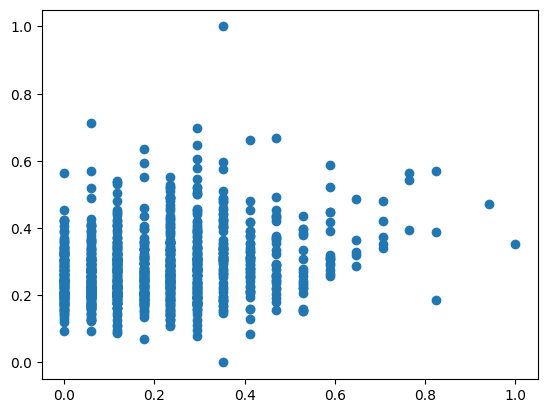

In [ ]:
# plot the two values to view distribution
plt.clf()
plt.scatter(imdb_simple['IMDB_Rating'], imdb_simple['Runtime in Minutes'])
plt.show()

K-Means

In [ ]:
# create a model to determine the clusters
kmeans = KMeans(n_clusters = 3, n_init="auto")
kmeans.fit(imdb_simple)
y_kmeans = kmeans.predict(imdb_simple)

In [ ]:
centroids = kmeans.cluster_centers_
print(centroids)

[[0.06264501 0.26316453]
 [0.47576767 0.36407347]
 [0.2507891  0.27049311]]


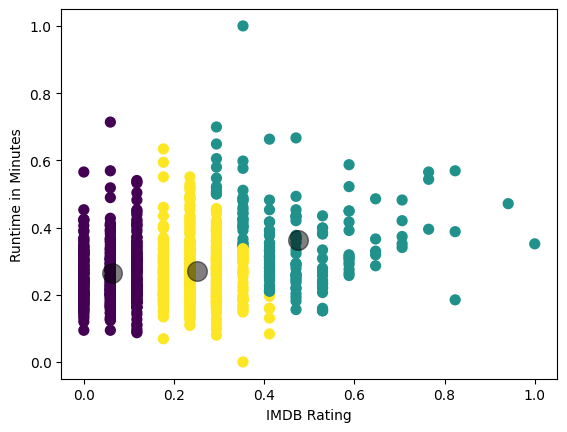

In [ ]:
plt.clf()
plt.scatter(imdb_simple['IMDB_Rating'], imdb_simple['Runtime in Minutes'], c=y_kmeans, s=50)
plt.scatter(centroids[:, 0], centroids[:, 1], c='black', s=200, alpha=0.5)
plt.xlabel('IMDB Rating')
plt.ylabel('Runtime in Minutes')
plt.show()

In [ ]:
def calculate_sse(X, max_num_clusters):
    sse = {}
    for k in range(1, max_num_clusters):
        kmeans = KMeans(n_clusters=k, n_init = "auto", max_iter=1000).fit(X)
        sse[k] = kmeans.inertia_ # Inertia: Sum of distances of samples to their closest cluster center

    plt.figure()
    plt.plot(list(sse.keys()), list(sse.values()))
    plt.xlabel("Number of cluster")
    plt.ylabel("SSE")
    plt.show()



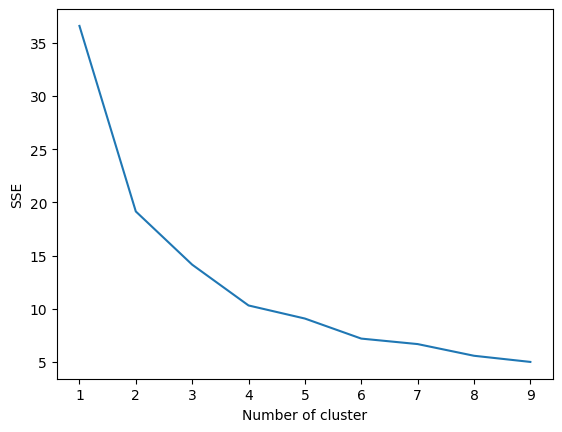

In [ ]:
# Using the function defined above we can find the optimal number of clusters is 4
calculate_sse(imdb_simple, 10)

In [ ]:
# we repeat the process using 4 clusters
kmeans = KMeans(n_clusters = 4, n_init="auto")
kmeans.fit(imdb_simple)
y_kmeans = kmeans.predict(imdb_simple)
centroids = kmeans.cluster_centers_

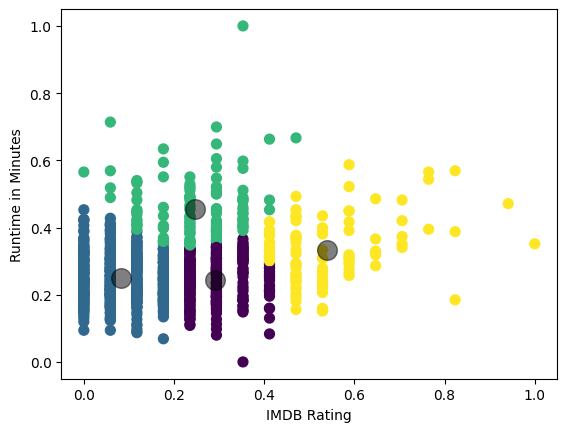

In [ ]:
# plot the new clusters
plt.clf()
plt.scatter(imdb_simple['IMDB_Rating'], imdb_simple['Runtime in Minutes'], c=y_kmeans, s=50)
plt.scatter(centroids[:, 0], centroids[:, 1], c='black', s=200, alpha=0.5)
plt.xlabel('IMDB Rating')
plt.ylabel('Runtime in Minutes')
plt.show()

In [ ]:
# From the graph we can see that based on the centroids movies with a longer runtime tend not to receive the highest ratings.
# Movies with a shorter runtime tend to get lower ratings as well

DBSCAN

In [ ]:
clustering = DBSCAN(eps=0.05, min_samples=3).fit(imdb_simple)

In [ ]:
y_dbscan = clustering.labels_

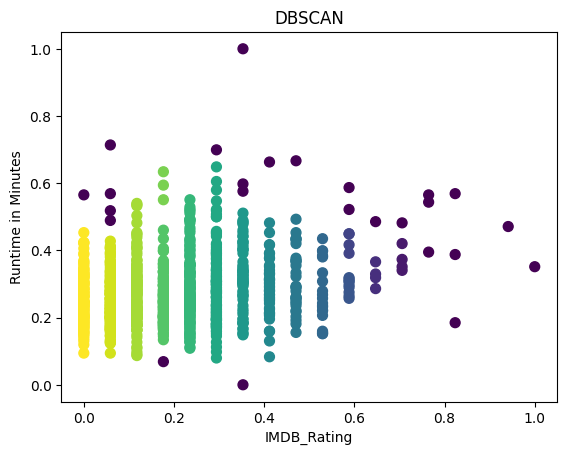

In [ ]:
plt.clf()
plt.scatter(imdb_simple['IMDB_Rating'], imdb_simple['Runtime in Minutes'], c=y_dbscan, s=50)
plt.xlabel('IMDB_Rating')
plt.ylabel('Runtime in Minutes')
plt.title('DBSCAN')
plt.show()

PCA

In [ ]:
pca = PCA(n_components=2).fit(X)

In [ ]:
pca.explained_variance_

array([0.33438099, 0.23061925])

In [ ]:
X

,IMDB_Rating,Drama,Crime,Action,Adventure,Biography,History,Sci-Fi,Romance,Western,...,Animation,Family,War,Mystery,Music,Horror,Musical,Film-Noir,Sport,Runtime in Minutes
0,1.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.351449
1,0.941176,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.471014
2,0.823529,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.387681
3,0.823529,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.568841
4,0.823529,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.184783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.253623
996,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.565217
997,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.264493
998,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.188406


In [ ]:
pca.explained_variance_ratio_

array([0.18587837, 0.12819847])

In [ ]:
round(pd.DataFrame(pca.components_.T,
             index = imdb.iloc[:, range(1,24)].columns,
             columns = ["PCA1", "PCA2"]),3)

,PCA1,PCA2
Released_Year,-0.014,0.018
Genre,-0.666,-0.084
IMDB_Rating,-0.152,0.450
Director,0.344,0.423
Star1,0.515,0.009
Star2,-0.136,0.019
Star3,-0.068,-0.003
Star4,0.106,0.079
Gross,-0.096,-0.296
Drama,0.007,0.003


In [ ]:
X_pca =  pca.transform(X)

In [ ]:
imdb_pca = pd.DataFrame(X_pca, columns = ["PCA1", "PCA2"])

<Figure size 640x480 with 0 Axes>

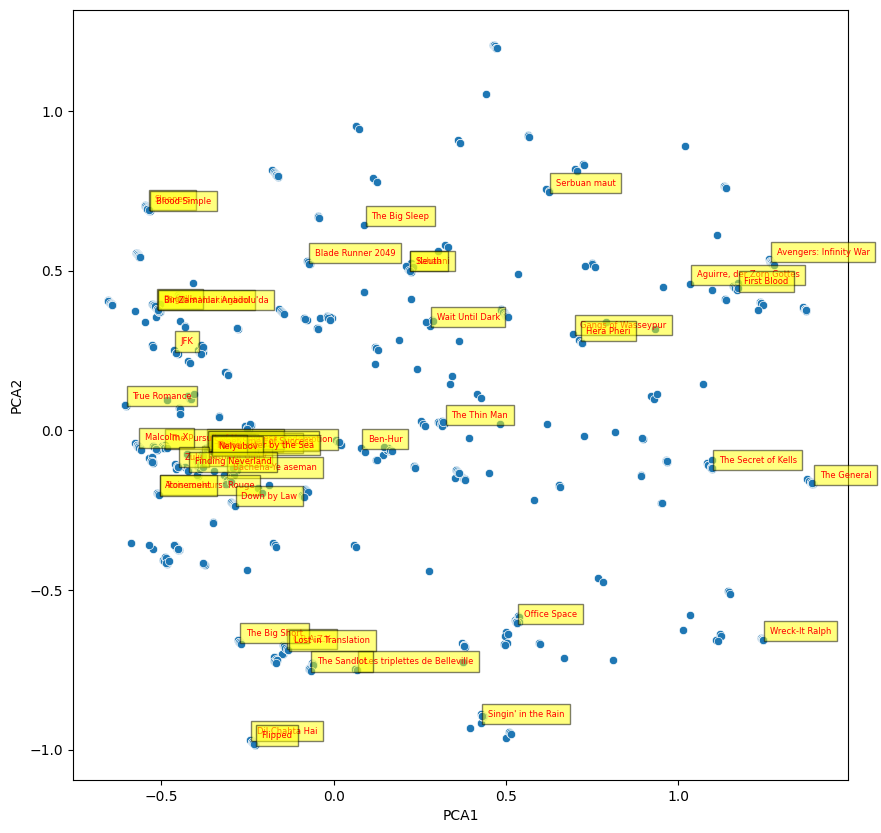

In [ ]:
plt.clf()
fig, ax = plt.subplots(figsize=(10, 10))
sns.scatterplot(data=imdb_pca, x="PCA1", y="PCA2")
for i in range(0, X_pca.shape[0], 20):
  plt.text(x=X_pca[i,0]+0.02,y=X_pca[i,1]+0.02,s=imdb["Series_Title"].iloc[i],
           fontdict=dict(color='red',size=6),
           bbox=dict(facecolor='yellow',alpha=0.5))
plt.show()

t-SNE

In [ ]:
tsne = TSNE(verbose=1)

In [ ]:
tsne_results = tsne.fit_transform(X)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1000 samples in 0.001s...
[t-SNE] Computed neighbors for 1000 samples in 0.201s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1000
[t-SNE] Mean sigma: 0.272793
[t-SNE] KL divergence after 250 iterations with early exaggeration: 63.500484
[t-SNE] KL divergence after 1000 iterations: 0.441342


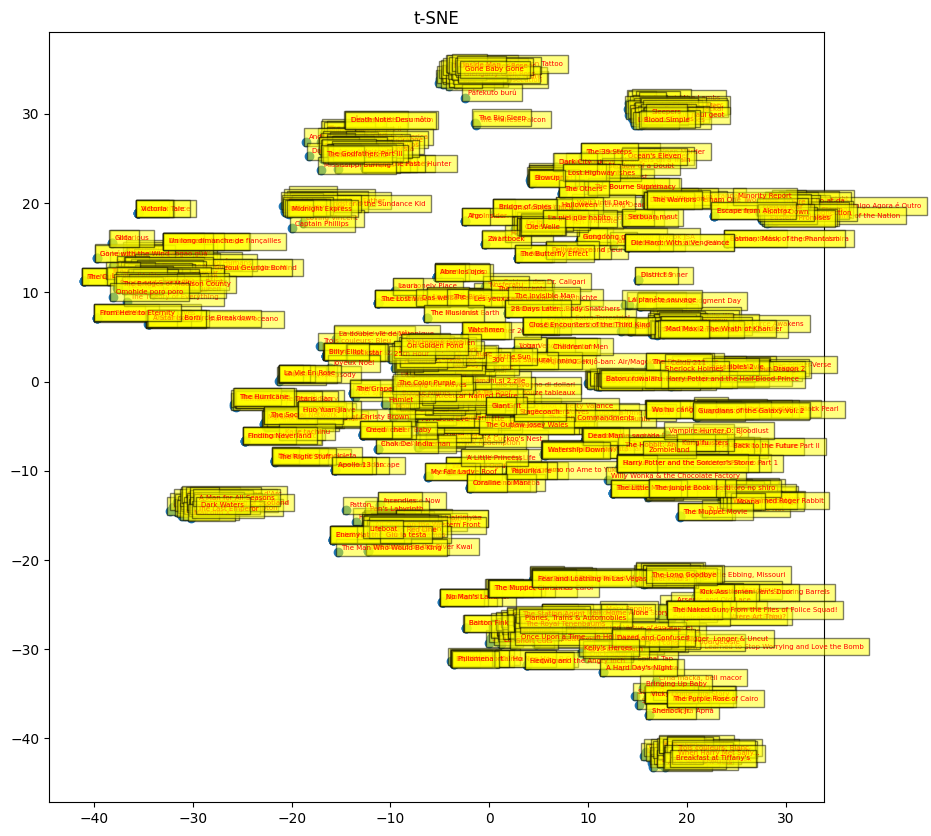

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
plt.scatter(tsne_results[:,0], y= tsne_results[:,1])
for i in range(tsne_results.shape[0]):
  plt.text(x=tsne_results[i,0]+0.3,y=tsne_results[i,1]+0.3,s=imdb["Series_Title"][i],
           fontdict=dict(color='red',size=5),
           bbox=dict(facecolor='yellow',alpha=0.5))
plt.title("t-SNE")
plt.show()


Text(0.5, 1.0, 't-SNE')

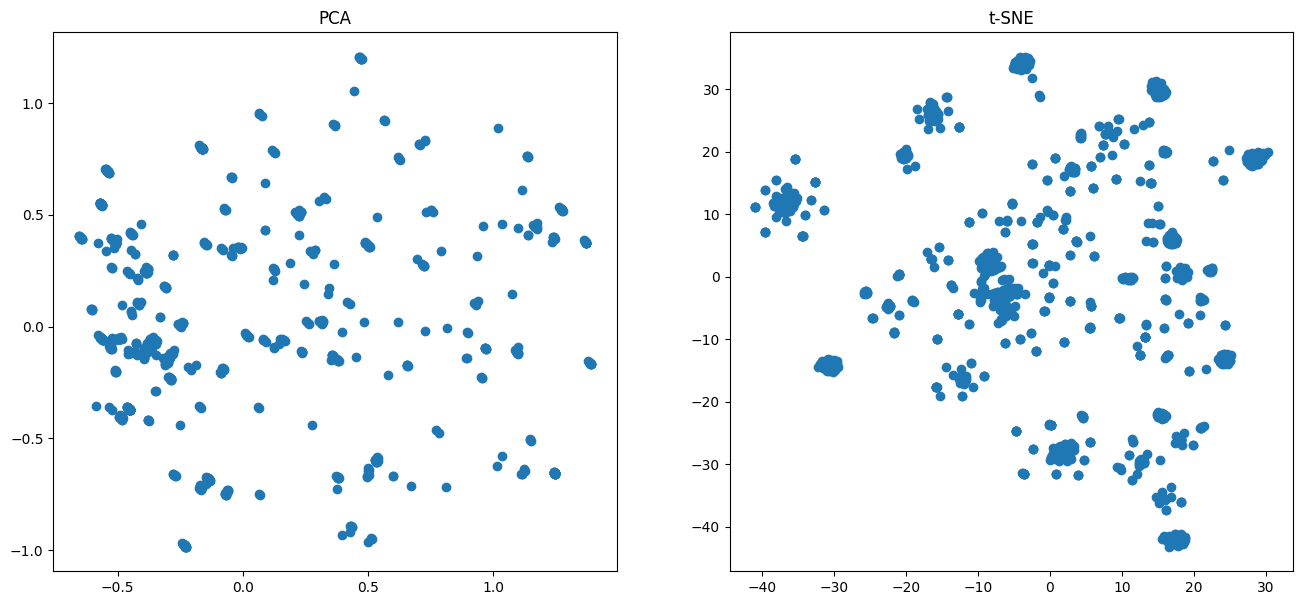

In [ ]:
plt.figure(figsize=(16,7))
ax1 = plt.subplot(1, 2, 1)
plt.scatter(X_pca[:,0],X_pca[:,1])
plt.title("PCA")
ax2 = plt.subplot(1, 2, 2)
plt.scatter(tsne_results[:,0], y= tsne_results[:,1])
plt.title("t-SNE")